# 04 · Phase 3 — Database model (UML → Django) and loading

**Input:** `data/clean/*.csv` (Phase-2 gate passed) · **Output:** SQLite database `webapp/db.sqlite3` + UML diagram `docs/uml_threatgraph.png`

The database is **derived** from the clean layer (it can be dropped and rebuilt any time). This notebook proves the load is *lossless*:
the content read back from the database is byte-for-byte the same CSV that Phase 2 validated.

| Check family | Question |
|---|---|
| model | do the models, migration files and admin agree (`check`, `makemigrations --check`)? |
| load | is the load idempotent and one-transaction? |
| counts | rows in DB == rows in clean (+ derived `Cwe`)? |
| content | DB → CSV bytes == Phase-2 manifest SHA-256 for all 9 tables? |
| integrity | foreign keys, unique constraints, validators, PROTECT/CASCADE behave as designed? |
| answers | do ORM queries give the same numbers as notebook 03? do the two views work? |

In [1]:
import sys, os, io, json, subprocess
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "sources.yaml").exists())
WEBAPP = ROOT / "webapp"
assert (WEBAPP / "manage.py").exists() and (WEBAPP / "catalog" / "models.py").exists(), (
    "Django project missing. In the repo root run:  django-admin startproject threatgraph_site webapp ; cd webapp ; python manage.py startapp catalog  "
    "(then copy the Phase-3 files, see webapp/README.md)")
sys.path[:0] = [str(ROOT / "src"), str(WEBAPP)]
os.environ["DJANGO_SETTINGS_MODULE"] = "threatgraph_site.settings"
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"       # Jupyter runs an event loop; the Django ORM refuses to run in it otherwise (standard notebook workaround)
import django; django.setup()
import pandas as pd
from IPython.display import display, Image
from django.apps import apps
from django.core.management import call_command
from django.core.exceptions import ValidationError
from django.db import connection, transaction, IntegrityError, models as djm
from django.db.models import Max, Count
from django.db.models.functions import Length
from django.db.models.deletion import ProtectedError
from django.test import Client
from django.test.utils import setup_test_environment
from threatgraph import config, cleaning as C
from threatgraph.integrity import sha256_bytes
import catalog.models as M
pd.set_option("display.max_columns", 30, "display.max_colwidth", 80, "display.width", 200)
SRC = config.load_sources(); CLEAN = config.CLEAN_DIR
clean_manifest = json.loads((CLEAN / "manifest.json").read_text())
assert json.loads((CLEAN / "phase2_validation_report.json").read_text())["all_passed"], "Phase 2 gate not passed"
print("Django", django.get_version(), "| DB:", connection.settings_dict["NAME"])

checks = []
def check(family, name, ok, detail=""):
    checks.append({"family": family, "name": name, "ok": bool(ok), "detail": str(detail)}); return bool(ok)

Django 5.2.18 | DB: /home/tavaa/Advanced_data_management/ThreatGraph/webapp/db.sqlite3


## 1 · Model checks (and the UML)

In [2]:
buf = io.StringIO(); call_command("check", stdout=buf)
check("model", "manage.py check (models + admin)", "no issues" in buf.getvalue(), buf.getvalue().strip())
call_command("makemigrations", "catalog", interactive=False, verbosity=0)           # creates 0001 if missing, otherwise no-op
buf = io.StringIO()
try: call_command("makemigrations", "--check", "--dry-run", stdout=buf); in_sync = True
except SystemExit: in_sync = False
check("model", "migration files are in sync with models.py", in_sync, buf.getvalue().strip())
models_ = list(apps.get_app_config("catalog").get_models())
check("model", "10 models (9 clean tables + derived Cwe)", len(models_) == 10, [m.__name__ for m in models_])
check("model", "all 10 models registered in the admin", all(m in __import__("django.contrib.admin", fromlist=["site"]).site._registry for m in models_))
call_command("migrate", verbosity=0)
display(pd.DataFrame({"model": [m.__name__ for m in models_], "table": [m._meta.db_table for m in models_],
                      "fields": [len(m._meta.concrete_fields) for m in models_]}))

,model,table,fields
0,Vulnerability,catalog_vulnerability,12
1,Cwe,catalog_cwe,2
2,KevCwe,catalog_kevcwe,3
3,NvdRecord,catalog_nvdrecord,13
4,NvdCveCwe,catalog_nvdcvecwe,5
5,AttackTactic,catalog_attacktactic,4
6,AttackTechnique,catalog_attacktechnique,9
7,AttackTechniqueTactic,catalog_attacktechniquetactic,3
8,PkevMapping,catalog_pkevmapping,7
9,PkevMappingReference,catalog_pkevmappingreference,4


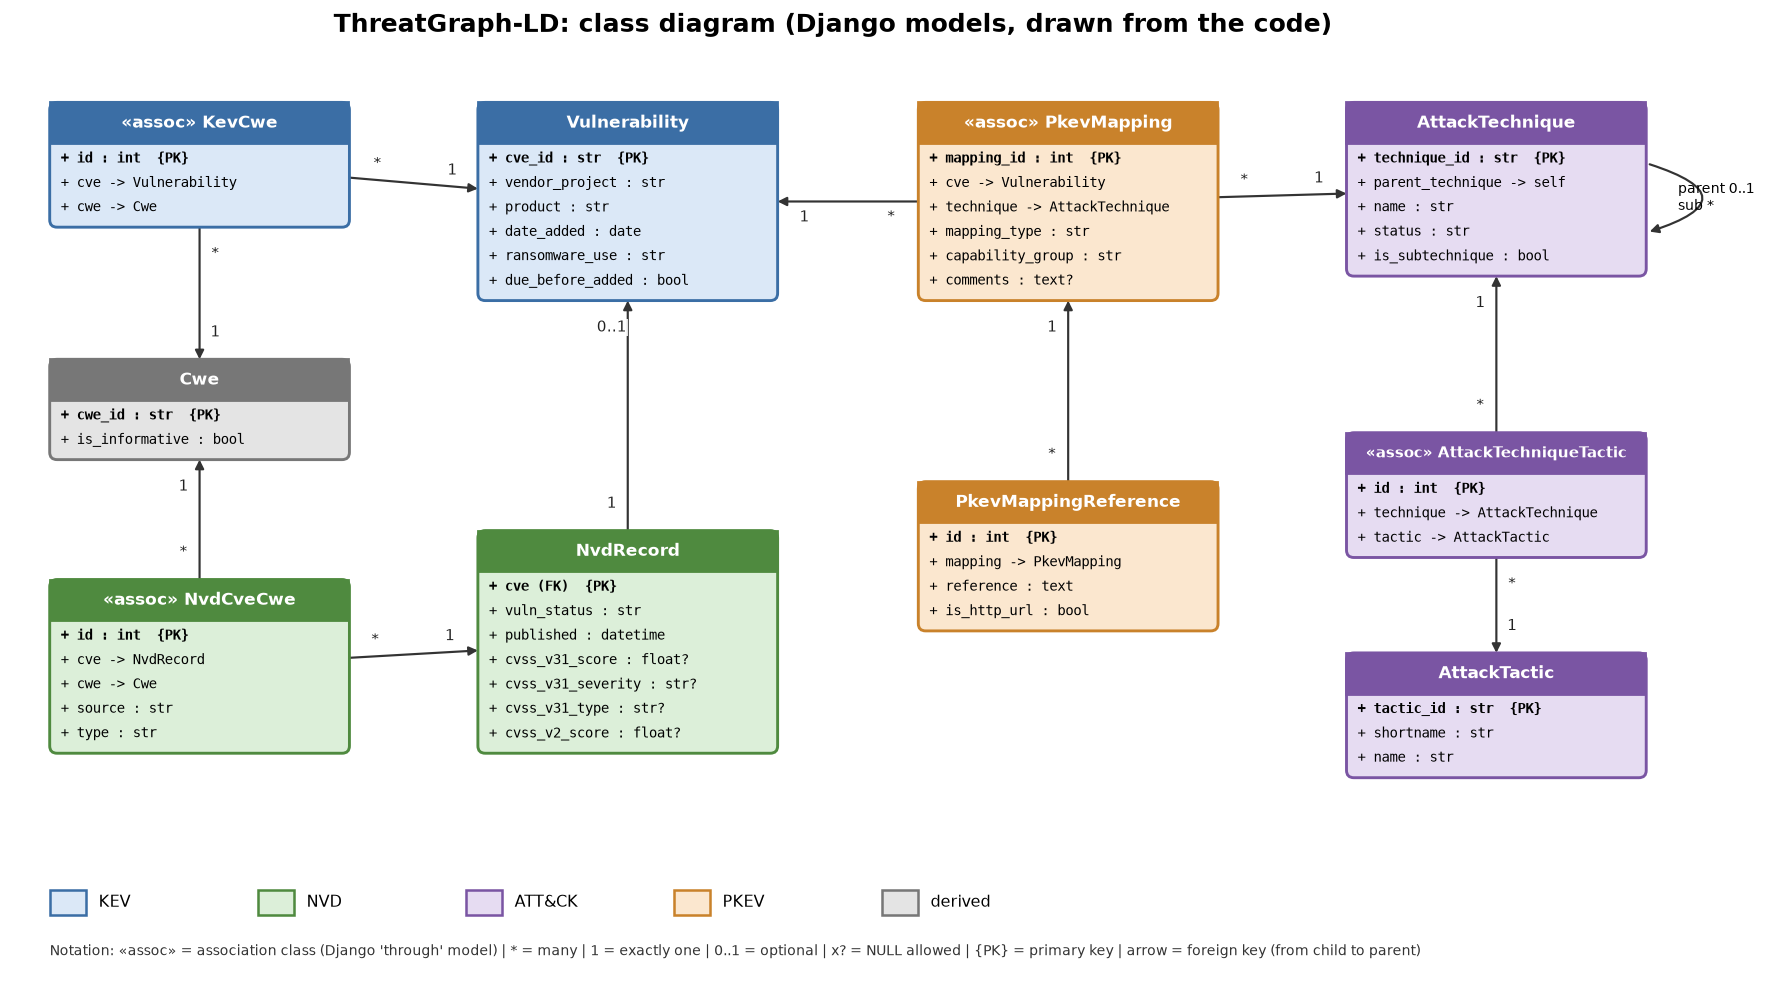

In [3]:
r = subprocess.run([sys.executable, "make_uml.py"], cwd=WEBAPP, capture_output=True, text=True)
png = ROOT / "docs" / "uml_threatgraph.png"
check("model", "make_uml.py runs and writes docs/uml_threatgraph.png", r.returncode == 0 and png.stat().st_size > 20_000, r.stdout.strip() or r.stderr[-300:])
display(Image(filename=str(png), width=1000))

## 2 · Load `data/clean/` → database (idempotent, one transaction)

In [4]:
buf = io.StringIO(); call_command("load_clean_data", stdout=buf); print(buf.getvalue())
first = {m.__name__: m.objects.count() for m in models_}
call_command("load_clean_data", stdout=io.StringIO())                                   # run it AGAIN
second = {m.__name__: m.objects.count() for m in models_}
check("load", "running the loader twice gives identical counts (idempotent, no duplicates)", first == second, second)

  Cwe                         176
  Vulnerability             1,391
  KevCwe                    1,328
  NvdRecord                 1,391
  NvdCveCwe                 2,523
  AttackTactic                 14
  AttackTechnique             799
  AttackTechniqueTactic     1,051
  PkevMapping               1,183
  PkevMappingReference      2,256
loaded 12,112 rows from /home/tavaa/Advanced_data_management/ThreatGraph/data/clean



True

## 3 · Counts: database vs clean layer

In [5]:
TABLE2MODEL = {"kev_vulnerability": M.Vulnerability, "kev_cwe": M.KevCwe, "nvd_cve": M.NvdRecord, "nvd_cve_cwe": M.NvdCveCwe,
               "attack_tactic": M.AttackTactic, "attack_technique": M.AttackTechnique,
               "attack_technique_tactic": M.AttackTechniqueTactic, "pkev_mapping": M.PkevMapping,
               "pkev_mapping_reference": M.PkevMappingReference}
clean = {t: C.read_clean(t, CLEAN) for t in TABLE2MODEL}
rows = [{"clean table": t, "model": m.__name__, "clean rows": len(clean[t]), "DB rows": m.objects.count()} for t, m in TABLE2MODEL.items()]
n_cwe = len(set(clean["kev_cwe"].cwe_id) | set(clean["nvd_cve_cwe"].cwe_id))
rows.append({"clean table": "(derived)", "model": "Cwe", "clean rows": n_cwe, "DB rows": M.Cwe.objects.count()})
cnt = pd.DataFrame(rows); display(cnt)
check("counts", "DB rows == clean rows for all 9 tables + Cwe == distinct cwe ids", (cnt["clean rows"] == cnt["DB rows"]).all())
check("counts", "row counts == pinned expectations in config/sources.yaml",
      all(M_.objects.count() == SRC["expected_clean"]["rows"][t] for t, M_ in TABLE2MODEL.items()))

,clean table,model,clean rows,DB rows
0,kev_vulnerability,Vulnerability,1391,1391
1,kev_cwe,KevCwe,1328,1328
2,nvd_cve,NvdRecord,1391,1391
3,nvd_cve_cwe,NvdCveCwe,2523,2523
4,attack_tactic,AttackTactic,14,14
5,attack_technique,AttackTechnique,799,799
6,attack_technique_tactic,AttackTechniqueTactic,1051,1051
7,pkev_mapping,PkevMapping,1183,1183
8,pkev_mapping_reference,PkevMappingReference,2256,2256
9,(derived),Cwe,176,176


True

## 4 · Content: is the load lossless?
Read every table **back from the database**, serialize it with the same function Phase 2 used, and compare the SHA-256 with the Phase-2 manifest.
One equal hash per table = same rows, same values, same NULLs, same types.

In [6]:
def db_frame(table, model):
    spec = C.SCHEMA[table]
    if table == "nvd_cve_cwe":
        df = pd.DataFrame(list(model.objects.values("cve_id", "cwe_id", "source", "type", "cwe__is_informative"))).rename(columns={"cwe__is_informative": "is_informative"})
    else:
        df = pd.DataFrame(list(model.objects.values()))
    df = df[list(spec.columns)]
    for c, col in spec.columns.items():
        if col.dtype == "date": df[c] = pd.to_datetime(df[c])
        elif col.dtype == "datetime": df[c] = pd.to_datetime(df[c], utc=True)
        elif col.dtype == "int": df[c] = df[c].astype("Int64")
        elif col.dtype == "float": df[c] = df[c].astype("float64")
        elif col.dtype == "bool": df[c] = df[c].astype(bool)
        else: df[c] = df[c].astype("string")
    return df
res = []
for t, m in TABLE2MODEL.items():
    got = sha256_bytes(C.serialize(db_frame(t, m), t)); want = clean_manifest["tables"][t]["sha256"]
    res.append({"table": t, "match": got == want, "sha256(DB→CSV)": got[:16] + "…", "sha256(manifest)": want[:16] + "…"})
res = pd.DataFrame(res); display(res)
check("content", "DB → CSV bytes == Phase-2 manifest SHA-256, all 9 tables (lossless load)", res.match.all())
cw = {c.cwe_id: c.is_informative for c in M.Cwe.objects.all()}
check("content", "Cwe.is_informative == (id not NVD-CWE-noinfo/Other)", all(v == (k not in C.NONINFORMATIVE_CWE) for k, v in cw.items()))

,table,match,sha256(DB→CSV),sha256(manifest)
0,kev_vulnerability,True,fc0c9410db476d57…,fc0c9410db476d57…
1,kev_cwe,True,b84bc6036a202b16…,b84bc6036a202b16…
2,nvd_cve,True,435b99c03249cd74…,435b99c03249cd74…
3,nvd_cve_cwe,True,51ec143965c24292…,51ec143965c24292…
4,attack_tactic,True,7e2e881702e4765d…,7e2e881702e4765d…
5,attack_technique,True,912ea691422248ae…,912ea691422248ae…
6,attack_technique_tactic,True,3008af112e5ab1b4…,3008af112e5ab1b4…
7,pkev_mapping,True,6b76edf9253c3e84…,6b76edf9253c3e84…
8,pkev_mapping_reference,True,c9111e106ef37a8d…,c9111e106ef37a8d…


True

## 5 · Integrity: constraints behave as designed

In [7]:
with connection.cursor() as cur:
    cur.execute("PRAGMA foreign_key_check"); fk = cur.fetchall()
check("integrity", "PRAGMA foreign_key_check returns no violation", fk == [], fk[:3])
# CharField lengths: would the data fit in a stricter database (PostgreSQL enforces max_length)?
too_long = []
for m in models_:
    for f in m._meta.concrete_fields:
        if isinstance(f, djm.CharField):
            mx = m.objects.aggregate(x=Max(Length(f.name)))["x"] or 0
            if mx > f.max_length: too_long.append((m.__name__, f.name, mx, f.max_length))
check("integrity", "every CharField max_length >= longest stored value", not too_long, too_long)

True

In [8]:
def rejected(fn, exc=(IntegrityError,)):
    """Negative test: run fn inside a transaction that is ALWAYS rolled back; True if the database/model refused it."""
    try:
        with transaction.atomic():
            fn(); connection.check_constraints()          # FK constraints are checked at commit: force it here
            raise _Rollback()
    except _Rollback: return False
    except exc: return True
class _Rollback(Exception): pass

v0 = M.Vulnerability.objects.first(); t0 = M.AttackTechnique.objects.get(technique_id="T1190")
kc = M.KevCwe.objects.first(); pm = M.PkevMapping.objects.first()
neg = [
 ("duplicate (cve, cwe) in KevCwe", rejected(lambda: M.KevCwe.objects.create(cve_id=kc.cve_id, cwe_id=kc.cwe_id))),
 ("duplicate (cve, technique, type) in PkevMapping", rejected(lambda: M.PkevMapping.objects.create(mapping_id=999999, cve_id=pm.cve_id, technique_id=pm.technique_id, mapping_type=pm.mapping_type, capability_group="x", status="complete"))),
 ("PkevMapping -> unknown technique (FK)", rejected(lambda: M.PkevMapping.objects.create(mapping_id=999998, cve_id=v0.cve_id, technique_id="T9999", mapping_type="primary_impact", capability_group="x", status="complete"))),
 ("KevCwe -> unknown CVE (FK)", rejected(lambda: M.KevCwe.objects.create(cve_id="CVE-1999-0001", cwe_id=kc.cwe_id))),
 ("second NvdRecord for the same CVE (one-to-one)", rejected(lambda: M.NvdRecord.objects.create(cve_id=v0.cve_id, source_identifier="x", published=v0.nvd.published, last_modified=v0.nvd.last_modified, vuln_status="Analyzed", description_en="x", n_references=0))),
 ("delete a technique that PKEV uses (PROTECT)", rejected(lambda: t0.delete(), exc=(ProtectedError,))),
]
def invalid(obj, field): 
    try: obj.full_clean(); return False
    except ValidationError as e: return field in e.message_dict
n = M.NvdRecord.objects.exclude(cvss_v31_score=None).first()
n.cvss_v31_score = 11.0
neg.append(("validator: CVSS score 11", invalid(n, "cvss_v31_score")))
neg.append(("validator: cve_id 'CVE-X'", invalid(M.Vulnerability(cve_id="CVE-X"), "cve_id")))
neg.append(("validator: unknown mapping_type", invalid(M.PkevMapping(mapping_type="guess"), "mapping_type")))
cascade = []
def _cascade():
    cve = M.Vulnerability.objects.get(cve_id=v0.cve_id); cve.delete()
    cascade.append((M.NvdRecord.objects.filter(cve_id=v0.cve_id).count(), M.KevCwe.objects.filter(cve_id=v0.cve_id).count()))
    raise _Rollback()
try:
    with transaction.atomic(): _cascade()
except _Rollback: pass
neg.append(("delete a CVE cascades to its NvdRecord and KevCwe rows (CASCADE)", cascade == [(0, 0)]))
neg = pd.DataFrame(neg, columns=["attempt", "refused / behaved as designed"]); display(neg)
check("integrity", f"{len(neg)} constraint / validator / on_delete tests behave as designed", neg.iloc[:, 1].all())
check("integrity", "negative tests left the database unchanged (rolled back)", {m.__name__: m.objects.count() for m in models_} == first)

,attempt,refused / behaved as designed
0,"duplicate (cve, cwe) in KevCwe",True
1,"duplicate (cve, technique, type) in PkevMapping",True
2,PkevMapping -> unknown technique (FK),True
3,KevCwe -> unknown CVE (FK),True
4,second NvdRecord for the same CVE (one-to-one),True
5,delete a technique that PKEV uses (PROTECT),True
6,validator: CVSS score 11,True
7,validator: cve_id 'CVE-X',True
8,validator: unknown mapping_type,True
9,delete a CVE cascades to its NvdRecord and KevCwe rows (CASCADE),True


True

## 6 · Answers: do ORM queries reproduce the numbers of notebook 03?
Same questions, different engine (SQL via the ORM instead of pandas). Agreement = the model preserved the meaning of the data.

In [9]:
exp = SRC["expected_clean"]["cross_source"]
q = {
 "kev_cves_with_pkev_mapping": M.Vulnerability.objects.filter(mappings__isnull=False).distinct().count(),
 "kev_cves_without_pkev_mapping": M.Vulnerability.objects.filter(mappings__isnull=True).count(),
 "with CVSS v3.1": M.NvdRecord.objects.filter(cvss_v31_score__isnull=False).count(),
 "with an informative CWE (NVD)": M.NvdCveCwe.objects.filter(cwe__is_informative=True).values("cve_id").distinct().count(),
 "techniques used by PKEV": M.PkevMapping.objects.values("technique_id").distinct().count(),
 "active techniques": M.AttackTechnique.objects.filter(status="active").count(),
 "due_before_added": M.Vulnerability.objects.filter(due_before_added=True).count(),
 "ransomware known": M.Vulnerability.objects.filter(ransomware_use="known").count(),
 "subtechniques without existing parent": M.AttackTechnique.objects.filter(is_subtechnique=True, parent_technique__isnull=True).count(),
 "techniques without tactic": M.AttackTechnique.objects.filter(tactics__isnull=True).count(),
}
want = {"kev_cves_with_pkev_mapping": exp["kev_cves_with_pkev_mapping"], "kev_cves_without_pkev_mapping": exp["kev_cves_without_pkev_mapping"],
        "with CVSS v3.1": 1389, "with an informative CWE (NVD)": 1188, "techniques used by PKEV": 155, "active techniques": 656,
        "due_before_added": SRC["known_anomalies"]["kev_due_before_added"], "ransomware known": 291,
        "subtechniques without existing parent": 0, "techniques without tactic": 0}
cmp = pd.DataFrame({"ORM": q, "notebook 03 / pinned": want}); display(cmp)
check("answers", "ORM answers == notebook 03 / pinned numbers", (cmp["ORM"] == cmp["notebook 03 / pinned"]).all())

,ORM,notebook 03 / pinned
kev_cves_with_pkev_mapping,419,419
kev_cves_without_pkev_mapping,972,972
with CVSS v3.1,1389,1389
with an informative CWE (NVD),1188,1188
techniques used by PKEV,155,155
active techniques,656,656
due_before_added,15,15
ransomware known,291,291
subtechniques without existing parent,0,0
techniques without tactic,0,0


True

In [10]:
# One CVE seen through the four sources (this join is the whole point of the project)
v = M.Vulnerability.objects.select_related("nvd").get(cve_id="CVE-2024-34102")
print(v); print("NVD :", v.nvd, "| CVSS v3.1:", v.nvd.cvss_v31_score, v.nvd.cvss_v31_severity)
print("CWE (KEV):", [c.cwe_id for c in v.cwes.all()], "| CWE (NVD):", [(x.cwe_id, x.source) for x in v.nvd.nvdcvecwe_set.all()])
for mp in v.mappings.select_related("technique"):
    print("ATT&CK:", mp.technique, "|", mp.mapping_type, "| tactics:", [t.shortname for t in mp.technique.tactics.all()])

CVE-2024-34102 (Adobe Commerce and Magento Open Source)
NVD : NVD CVE-2024-34102 [Analyzed] | CVSS v3.1: 9.8 CRITICAL
CWE (KEV): ['CWE-611'] | CWE (NVD): [('CWE-611', 'psirt@adobe.com')]
ATT&CK: T1190 Exploit Public-Facing Application | exploitation_technique | tactics: ['initial-access']
ATT&CK: T1059 Command and Scripting Interpreter | primary_impact | tactics: ['execution']
ATT&CK: T1005 Data from Local System | secondary_impact | tactics: ['collection']


In [11]:
setup_test_environment(); c = Client()
r = c.get("/stats/"); stats = r.json()
check("answers", "GET /stats/ -> 200 and counts == database", r.status_code == 200 and stats == first, stats)
r = c.get("/vulnerability/CVE-2024-34102/"); j = r.json()
check("answers", "GET /vulnerability/CVE-2024-34102/ -> 200 with KEV, NVD and ATT&CK parts", r.status_code == 200 and j["kev"] and j["nvd"] and j["attack"], list(j))
unmapped = M.Vulnerability.objects.filter(mappings__isnull=True).first().cve_id
r = c.get(f"/vulnerability/{unmapped}/"); check("answers", "an unmapped CVE returns attack == [] (not mapped by PKEV)", r.status_code == 200 and r.json()["attack"] == [], unmapped)
check("answers", "unknown CVE -> 404", c.get("/vulnerability/CVE-1999-0001/").status_code == 404)
check("answers", "/ redirects to /admin/", c.get("/").status_code == 302)

Not Found: /vulnerability/CVE-1999-0001/


True

## 7 · Phase gate

In [12]:
rep = pd.DataFrame(checks)
summary = rep.groupby("family").ok.agg(passed="sum", total="count"); display(summary)
failed = rep[~rep.ok]; print("FAILED:", failed.to_dict("records") if len(failed) else "none")
assert failed.empty, "Phase 3 gate failed"
out = ROOT / "docs" / "phase3_validation_report.json"
out.write_text(json.dumps({"phase": 3, "django": django.get_version(), "all_passed": True, "summary": summary.reset_index().to_dict("records"),
                           "checks": checks, "clean_manifest_sha256": sha256_bytes((CLEAN / "manifest.json").read_bytes())}, indent=2) + "\n")
print("PHASE 3 GATE: PASSED ->", len(checks), "checks | report:", out.relative_to(ROOT))

,passed,total
family,,
answers,6,6
content,2,2
counts,2,2
integrity,4,4
load,1,1
model,5,5


FAILED: none
PHASE 3 GATE: PASSED -> 20 checks | report: docs/phase3_validation_report.json


## 8 · What this does **not** prove
* The database is as good as the clean layer: it inherits every limit listed in Phase 2 (consistent ≠ true).
* Tested on **SQLite** only. PostgreSQL would also enforce `max_length` and treat the long `reference` unique index differently [UNCERTAIN, not run].
* No performance test: 12 k rows load in ~2 s, but nothing here says how it behaves with the full NVD (300 k records).
* The two views are demo endpoints; the REST API, JSON-LD and content negotiation are Phase 4.

**Next (Phase 4, concept only):** REST API (DRF) + JSON-LD + a Python client script that calls it.